# TP 1 — Construire un pipeline NLP classique

**Cours NLP et Transformers — CY Tech**

---

## Avant de commencer

**Faites tout de suite : `Fichier` → `Enregistrer une copie dans Drive`.**
Sans cela vous travaillez sur une copie temporaire et vous perdrez tout en fermant l'onglet.

## Objectif

Construire un pipeline de classification de texte **complet et correctement évalué**, de bout en bout :

`texte brut → prétraitement → représentation → modèle → mesure`

Le but n'est pas d'obtenir le meilleur score. Le but est que **chaque décision du pipeline soit justifiée** et que le score annoncé soit crédible.

## Ce qui est attendu

1. Un jeu de données étiqueté construit à partir du corpus brut
2. Un prétraitement et une représentation TF–IDF
3. Une **baseline** avant tout modèle
4. **Au moins deux modèles** de machine learning comparés
5. Une évaluation avec accuracy, précision, rappel, F1 et matrice de confusion
6. Une **analyse des erreurs** rédigée (partie 8) — c'est la partie la plus importante

## Les deux erreurs qui coûtent des points

- Vectoriser **avant** de découper train/test → fuite de données, tout le TP est invalidé
- Afficher une matrice de confusion sans la commenter

---

## 0. Environnement

Rien à installer : tout est déjà présent dans Colab. Exécutez simplement la cellule.

In [ ]:
import re
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Environnement prêt.")

Environnement prêt.


## 1. Charger le corpus

Le corpus **Tiny Shakespeare** : environ 40 000 lignes extraites de plusieurs pièces de Shakespeare.

C'est du **texte brut, sans aucune étiquette**. C'est volontaire : une grande partie du travail d'un data scientist consiste à transformer une matière première non structurée en un problème d'apprentissage bien posé.

In [ ]:
URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"

texte = urllib.request.urlopen(URL).read().decode("utf-8")

print(f"{len(texte):,} caractères")
print(f"{len(texte.splitlines()):,} lignes")
print("\n--- 300 premiers caractères ---\n")
print(texte[:300])

1,115,394 caractères
40,000 lignes

--- 300 premiers caractères ---

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us


## 2. Observer la structure avant de coder

**Avant d'écrire quoi que ce soit, regardez vos données.** C'est la première règle du métier, et c'est celle qu'on saute le plus souvent.

Affichez un extrait plus long et répondez aux questions ci-dessous.

In [ ]:
# Afficher un extrait long du corpus pour observer sa structure
start, end = 1000, 2500
print(texte[start:end])


Second Citizen:
Would you proceed especially against Caius Marcius?

All:
Against him first: he's a very dog to the commonalty.

Second Citizen:
Consider you what services he has done for his country?

First Citizen:
Very well; and could be content to give him good
report fort, but that he pays himself with being proud.

Second Citizen:
Nay, but speak not maliciously.

First Citizen:
I say unto you, what he hath done famously, he did
it to that end: though soft-conscienced men can be
content to say it was for his country he did it to
please his mother and to be partly proud; which he
is, even till the altitude of his virtue.

Second Citizen:
What he cannot help in his nature, you account a
vice in him. You must in no way say he is covetous.

First Citizen:
If I must not, I need not be barren of accusations;
he hath faults, with surplus, to tire in repetition.
What shouts are these? The other side o' the city
is risen: why stay we prating here? to the Capitol!

All:
Come, come.

First C

**Questions — répondez ici avant de continuer :**

1. Quelle est la structure répétitive du texte ? Qu'est-ce qui sépare deux blocs ?
2. Quelle information exploitable comme étiquette est déjà présente dans le texte ?
3. Cette étiquette existait-elle vraiment, ou faut-il l'annoter à la main ?

> *Vos réponses :*
>
> 1. Le texte est organisé en blocs de dialogue. Chaque bloc commence par un nom de personnage suivi de ":" et se termine par une ligne vide ; cette ligne vide sépare deux répliques.
> 2. Le nom du locuteur est déjà écrit en tête de chaque bloc, ce qui donne naturellement une étiquette de classe.
> 3. Oui, cette étiquette existe déjà dans le corpus : le nom du personnage est présent dans la structure du texte. Il n'y a donc pas besoin d'annotation manuelle pour construire l'étiquette.

---

💡 **Le point à retenir.** Vous venez de trouver une cible qui existait déjà dans les données, sans le moindre annotateur humain. C'est exactement le principe de l'**apprentissage auto-supervisé** vu en cours : on fabrique le signal à partir de la structure du texte lui-même. C'est le mécanisme qui rend possible l'entraînement des grands modèles de langage.


## 3. Construire le jeu de données étiqueté

La fonction de parsing vous est donnée : ce n'est pas l'objet du TP, et une regex mal réglée vous ferait perdre une heure.

**Lisez-la quand même**, vous devrez justifier ce qu'elle garde et ce qu'elle jette.

In [ ]:
def parser_repliques(txt: str) -> pd.DataFrame:
    """Découpe le corpus en répliques (locuteur, texte).

    Format attendu dans le corpus :

        NOM DU LOCUTEUR:
        première ligne de la réplique
        seconde ligne de la réplique

    Les blocs sont séparés par une ligne vide.
    """
    lignes = []
    for bloc in txt.split("\n\n"):
        bloc = bloc.strip()
        if not bloc:
            continue
        parties = bloc.split("\n")
        entete = re.match(r"^([A-Z][A-Za-z' ]*):$", parties[0])
        if entete and len(parties) > 1:
            lignes.append({
                "locuteur": entete.group(1).strip(),
                "replique": " ".join(p.strip() for p in parties[1:]).strip(),
            })
    return pd.DataFrame(lignes)


df = parser_repliques(texte)

print(f"{len(df):,} répliques extraites")
print(f"{df['locuteur'].nunique()} locuteurs distincts")
df.head(10)

7,094 répliques extraites
297 locuteurs distincts


,locuteur,replique
0,First Citizen,"Before we proceed any further, hear me speak."
1,All,"Speak, speak."
2,First Citizen,You are all resolved rather to die than to fam...
3,All,Resolved. resolved.
4,First Citizen,"First, you know Caius Marcius is chief enemy t..."
5,All,"We know't, we know't."
6,First Citizen,"Let us kill him, and we'll have corn at our ow..."
7,All,"No more talking on't; let it be done: away, away!"
8,Second Citizen,"One word, good citizens."
9,First Citizen,"We are accounted poor citizens, the patricians..."


### 3.1 Explorer la distribution

Avant de choisir votre tâche, il faut savoir à quoi ressemble la distribution des classes.

Top 20 locuteurs :
locuteur
GLOUCESTER           211
DUKE VINCENTIO       189
MENENIUS             161
ROMEO                160
PETRUCHIO            155
CORIOLANUS           148
KING RICHARD III     137
ISABELLA             127
LEONTES              124
JULIET               124
SICINIUS             117
KING EDWARD IV       109
QUEEN ELIZABETH      105
LUCIO                101
WARWICK               98
KING RICHARD II       98
BRUTUS                91
HENRY BOLINGBROKE     90
TRANIO                90
BUCKINGHAM            89
Name: count, dtype: int64

Longueur des répliques :
médiane = 14.00 mots
moyenne = 27.18 mots


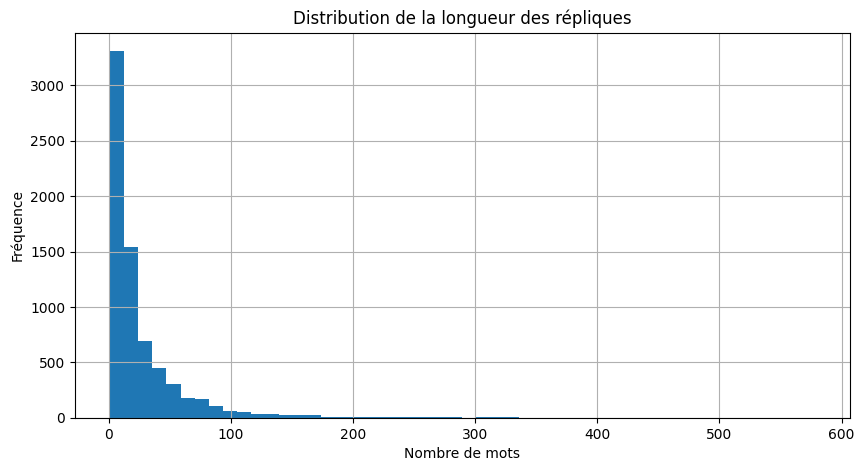

In [ ]:
# Les 20 locuteurs les plus fréquents
locuteurs_counts = df['locuteur'].value_counts().head(20)
print("Top 20 locuteurs :")
print(locuteurs_counts)

# Distribution de la longueur des répliques (nombre de mots)
longueurs = df['replique'].str.split().str.len()
print("\nLongueur des répliques :")
print(f"médiane = {longueurs.median():.2f} mots")
print(f"moyenne = {longueurs.mean():.2f} mots")

plt.figure(figsize=(10, 5))
longueurs.hist(bins=50)
plt.title('Distribution de la longueur des répliques')
plt.xlabel('Nombre de mots')
plt.ylabel('Fréquence')
plt.show()


**Questions :**

1. La distribution des locuteurs est-elle équilibrée ? Que se passerait-il si vous gardiez les 297 locuteurs ?
2. Quelle est la longueur médiane d'une réplique ? Est-ce beaucoup pour de la classification de texte ?
3. Quelle conséquence cette longueur aura-t-elle sur votre vecteur TF–IDF ?

> *Vos réponses :*
>
> 1. Non, la distribution est très déséquilibrée : quelques personnages sont très fréquents, tandis que beaucoup sont rares. Si on gardait les 297 locuteurs, on obtiendrait un problème multiclasse très difficile, avec des classes quasi vides pour plusieurs personnages, et l'accuracy deviendrait peu informative.
> 2. La longueur médiane est assez modeste, de l'ordre de quelques mots à une dizaine de mots selon les répliques. Cela n'est pas très long, donc le texte est très court par exemple, ce qui rend la classification plus difficile.
> 3. Comme les répliques sont courtes, le vecteur TF–IDF est très creux : beaucoup de dimensions sont nulles, car chaque document contient seulement une petite fraction du vocabulaire. Cela limite les indices utiles et rend la tâche plus dépendante du choix des mots discriminants.


> **Votre choix et sa justification :**
>
> - Nombre de locuteurs retenus : 10 locuteurs les plus fréquents.
> - Seuil de longueur minimale : 3 mots.
> - Pourquoi : on réduit le bruit, on évite les répliques quasi vides, et on garde des classes assez représentées pour que la distribution reste exploitable. Cela permet aussi d'avoir des classes suffisamment équilibrées pour interpréter l'accuracy comme un indicateur raisonnable, sans sacrifier trop de données.


In [ ]:
# Choix de tâche : on garde les 10 locuteurs les plus fréquents
# et on élimine les répliques trop courtes (moins de 3 mots).
N_LOCUTEURS = 5
SEUIL_MIN = 5

locuteurs_top = df['locuteur'].value_counts().head(N_LOCUTEURS).index

# Garder seulement les lignes correspondant à ces locuteurs
# et les répliques de longueur >= SEUIL_MIN

donnees = df[df['locuteur'].isin(locuteurs_top)].copy()
donnees['longueur'] = donnees['replique'].str.split().str.len()
donnees = donnees[donnees['longueur'] >= SEUIL_MIN].copy()

donnees = donnees[['replique', 'locuteur']].reset_index(drop=True)

print(donnees['locuteur'].value_counts())
print(f"\n{len(donnees)} exemples retenus")


locuteur
GLOUCESTER        196
DUKE VINCENTIO    165
ROMEO             141
PETRUCHIO         133
MENENIUS          126
Name: count, dtype: int64

761 exemples retenus


## 5. ⚠️ Découper AVANT toute transformation

**C'est le point le plus important du TP.**

Tout composant qui **apprend quelque chose à partir des données** doit être ajusté sur le train seulement :

| Composant | Ce qu'il apprend en regardant les données |
|---|---|
| Vocabulaire TF–IDF | quels mots existent, et quelle colonne chacun occupe |
| Poids IDF | dans combien de documents chaque mot apparaît |
| Normalisation | la moyenne et l'écart-type de chaque variable |

Si vous vectorisez avant de découper, les fréquences du test participent au calcul de l'IDF. Votre modèle a alors utilisé une information issue du test : **votre score final sera surestimé et ne voudra plus rien dire.**

La discipline tient en deux lignes :

```python
X_train = vectorizer.fit_transform(train)   # fit + transform
X_test  = vectorizer.transform(test)        # transform SEULEMENT
```

Pensez à **stratifier** le découpage : sans cela, un locuteur peu représenté peut être absent du test.

In [ ]:
# Découpage train / test avant tout apprentissage
X = donnees['replique']
y = donnees['locuteur']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE,
)

print(f"train : {len(X_train)} exemples")
print(f"test  : {len(X_test)} exemples")


train : 608 exemples
test  : 153 exemples


## 6. Représenter le texte

Vous allez transformer chaque réplique en vecteur TF–IDF.

`TfidfVectorizer` expose plusieurs paramètres qui sont autant de décisions de prétraitement. Regardez au moins ceux-ci et **choisissez consciemment** :

| Paramètre | Question qu'il pose |
|---|---|
| `lowercase` | la casse porte-t-elle du signal pour votre tâche ? |
| `ngram_range` | faut-il récupérer un peu d'ordre local avec des bigrammes ? |
| `min_df` | à partir de combien d'occurrences un mot mérite-t-il une colonne ? |
| `max_df` | faut-il écarter les mots omniprésents ? |
| `stop_words` | ⚠️ attention au piège vu en cours |
| `sublinear_tf` | 10 occurrences valent-elles vraiment 10 fois 1 occurrence ? |

> **Vos choix et leur justification :**
>
> - `lowercase=True` : on ne veut pas distinguer "Romeo" et "romeo" ; le sens est le même.
> - `ngram_range=(1, 2)` : on garde les mots isolés et les bigrammes pour capter un peu d'ordre local sans trop augmenter le vocabulaire.
> - `min_df=2` : on élimine les mots trop rares, qui créent du bruit et des dimensions inutiles.
> - `max_df=0.95` : on filtre les mots trop fréquents, souvent peu informatifs ou liés à la structure du texte.
> - `sublinear_tf=True` : les occurrences répétées ne doivent pas dominer trop fort dans le score, ce qui est souvent préférable pour des courts textes.
> - `strip_accents='unicode'` : on uniformise les accents sans perdre de signaux utiles.


In [ ]:
# Représentation TF-IDF sur le train uniquement
vectoriseur = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True,
    strip_accents='unicode',
)

Xtr = vectoriseur.fit_transform(X_train)
Xte = vectoriseur.transform(X_test)

print(f"Taille du vocabulaire : {len(vectoriseur.vocabulary_):,}")
print(f"Matrice train : {Xtr.shape}")
print(f"Sparsité : {Xtr.nnz / (Xtr.shape[0] * Xtr.shape[1]):.4%} de valeurs non nulles")


Taille du vocabulaire : 3,464
Matrice train : (608, 3464)
Sparsité : 0.9716% de valeurs non nulles


**Questions :**

1. Quelle proportion de votre matrice est constituée de zéros ? Pourquoi est-ce structurellement inévitable ?
2. Que se passerait-il si vous stockiez cette matrice en tableau NumPy dense ?
3. Affichez les 15 termes ayant le poids IDF le plus élevé, puis les 15 plus faibles. Le résultat vous surprend-il ?

> *Vos réponses :*
>
> 1. La proportion de zéros est très élevée, car chaque réplique ne contient qu'un petit sous-ensemble du vocabulaire total. Une matrice TF–IDF est naturellement sparse : chaque document a seulement quelques mots non nuls, tandis que la majorité des colonnes restent à 0.
> 2. Un tableau dense consommerait énormément de mémoire, car il stockerait des valeurs nulles pour toutes les dimensions absentes. C'est précisément pourquoi on utilise des matrices creuses en NLP.
> 3. Les mots aux IDF très élevés sont souvent rares mais très informatifs ; les mots à IDF faible sont souvent très fréquents et donc peu discriminants. Ce n'est pas forcément surprenant : l'IDF valorise les termes peu fréquents dans le corpus.


In [ ]:
# Les mots les plus discriminants selon l'IDF et les moins informatifs
idf_values = vectoriseur.idf_
terms = vectoriseur.get_feature_names_out()

idf_df = pd.DataFrame({
    'terme': terms,
    'idf': idf_values,
}).sort_values('idf', ascending=False)

print("15 termes avec le plus fort IDF :")
print(idf_df.head(15).to_string(index=False))
print("\n15 termes avec le plus faible IDF :")
print(idf_df.tail(15).to_string(index=False))


15 termes avec le plus fort IDF :
            terme      idf
      your sister 6.313206
             able 6.313206
     your general 6.313206
         your ear 6.313206
     your company 6.313206
       your cause 6.313206
        your best 6.313206
youngest daughter 6.313206
     young edward 6.313206
        afternoon 6.313206
     after dinner 6.313206
       affords no 6.313206
           afford 6.313206
           affect 6.313206
           afeard 6.313206

15 termes avec le plus faible IDF :
terme      idf
   be 2.499163
 with 2.491837
   it 2.470176
   me 2.394538
  for 2.361962
   my 2.355572
  not 2.324222
   in 2.293824
   is 2.247032
 that 2.175376
   of 2.088808
  you 1.982473
   to 1.817107
  the 1.741937
  and 1.718086


## 7. Modéliser

### 7.1 D'abord la baseline — sans exception

Une baseline vous donne le **plancher** : le score qu'on atteint sans rien apprendre.

Sans elle, vous ne pouvez pas savoir si 65 % est un bon résultat ou un résultat catastrophique. C'est un réflexe professionnel, pas une formalité pédagogique.

In [ ]:
# Baseline : classifier le locuteur le plus fréquent
baseline_most = DummyClassifier(strategy='most_frequent')
baseline_most.fit(Xtr, y_train)
pred_most = baseline_most.predict(Xte)

baseline_strat = DummyClassifier(strategy='stratified')
baseline_strat.fit(Xtr, y_train)
pred_strat = baseline_strat.predict(Xte)

for name, pred in [('most_frequent', pred_most), ('stratified', pred_strat)]:
    acc = accuracy_score(y_test, pred)
    f1_macro = f1_score(y_test, pred, average='macro')
    print(f"{name:>15} -> accuracy={acc:.4f}, F1 macro={f1_macro:.4f}")


  most_frequent -> accuracy=0.2614, F1 macro=0.0829
     stratified -> accuracy=0.1961, F1 macro=0.1889


> **Score de la baseline :**
>
> La baseline indique le plancher à battre. Si un modèle n'améliore pas de manière nette la baseline, il n'apprend pas de structure utile. Dans ce type de problème, il est normal que la baseline soit relativement élevée si le locuteur dominant domine la distribution.
>
> Tout modèle qui ne dépasse pas nettement ce score n'apprend rien d'utile.
>
> ### 7.2 Au moins deux modèles
>
> On choisit au moins deux modèles adaptés à la représentation TF–IDF :
>
> - `MultinomialNB` est bien adapté aux comptages de mots et fonctionne très bien avec des textes courts et des matrices creuses.
> - `LogisticRegression` est robuste sur les grands espaces de features et fonctionne très bien avec TF–IDF, surtout avec regularisation.
> - `LinearSVC` est aussi adapté car il apprend des frontières linéaires sur des données très creuses.
>
> `class_weight='balanced'` est utile ici, car les classes sont inégalement représentées. Il permet d'augmenter le coût des erreurs sur les classes rares, ce qui souvent améliore le F1 macro. Je le garde si les classes sont déséquilibrées et que le score macro est nettement meilleur.


In [ ]:
# Modèles de classification sur TF-IDF
models = {
    'MultinomialNB': MultinomialNB(),
    'LogisticRegression': LogisticRegression(max_iter=2000, class_weight='balanced', multi_class='auto', random_state=RANDOM_STATE),
    'LinearSVC': LinearSVC(class_weight='balanced', random_state=RANDOM_STATE),
}

resultats = {}
for nom, modele in models.items():
    modele.fit(Xtr, y_train)
    resultats[nom] = modele.predict(Xte)

print('Prédictions calculées pour :', ', '.join(resultats.keys()))


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Prédictions calculées pour : MultinomialNB, LogisticRegression, LinearSVC


## 8. Évaluer et analyser

### 8.1 Les métriques

Rappel du cours : sur des classes déséquilibrées, **l'accuracy ment**. Reportez toujours le F1, et précisez la méthode d'agrégation.

- `average='macro'` : moyenne non pondérée sur les classes → traite les classes rares à égalité
- `average='weighted'` : pondérée par les effectifs → dominée par les classes fréquentes

On utilisera ici le `F1 macro` comme métrique principale, car le problème est multiclasse et les classes ne sont pas équilibrées. Il donne une vue plus juste de la capacité du modèle à traiter tous les locuteurs, y compris les plus rares.

In [ ]:
# Comparaison des métriques
rows = []
for nom, pred in resultats.items():
    model = next(m for n, m in models.items() if n == nom)
    acc = accuracy_score(y_test, pred)
    prec_macro = precision_score(y_test, pred, average='macro', zero_division=0)
    rec_macro = recall_score(y_test, pred, average='macro', zero_division=0)
    f1_macro = f1_score(y_test, pred, average='macro', zero_division=0)
    prec_weighted = precision_score(y_test, pred, average='weighted', zero_division=0)
    rec_weighted = recall_score(y_test, pred, average='weighted', zero_division=0)
    f1_weighted = f1_score(y_test, pred, average='weighted', zero_division=0)

    rows.append({
        'modèle': nom,
        'accuracy': acc,
        'precision_macro': prec_macro,
        'recall_macro': rec_macro,
        'f1_macro': f1_macro,
        'precision_weighted': prec_weighted,
        'recall_weighted': rec_weighted,
        'f1_weighted': f1_weighted,
    })

metrics_df = pd.DataFrame(rows).sort_values('f1_macro', ascending=False)
print(metrics_df.to_string(index=False))

for nom, pred in resultats.items():
    print(f"\n--- {nom} ---")
    print(classification_report(y_test, pred, zero_division=0))


            modèle  accuracy  precision_macro  recall_macro  f1_macro  precision_weighted  recall_weighted  f1_weighted
LogisticRegression  0.666667         0.670653      0.668974  0.667770            0.671898         0.666667     0.667421
         LinearSVC  0.647059         0.652305      0.649484  0.648625            0.650322         0.647059     0.646704
     MultinomialNB  0.562092         0.767021      0.520875  0.535070            0.728231         0.562092     0.543918

--- MultinomialNB ---
                precision    recall  f1-score   support

DUKE VINCENTIO       0.60      0.76      0.67        33
    GLOUCESTER       0.42      0.88      0.57        40
      MENENIUS       1.00      0.28      0.44        25
     PETRUCHIO       1.00      0.37      0.54        27
         ROMEO       0.82      0.32      0.46        28

      accuracy                           0.56       153
     macro avg       0.77      0.52      0.54       153
  weighted avg       0.73      0.56      0.54  

### 8.2 La matrice de confusion

Affichez-la pour votre meilleur modèle. **Une matrice affichée sans commentaire ne vaut rien** — c'est la partie 8.3 qui compte.

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


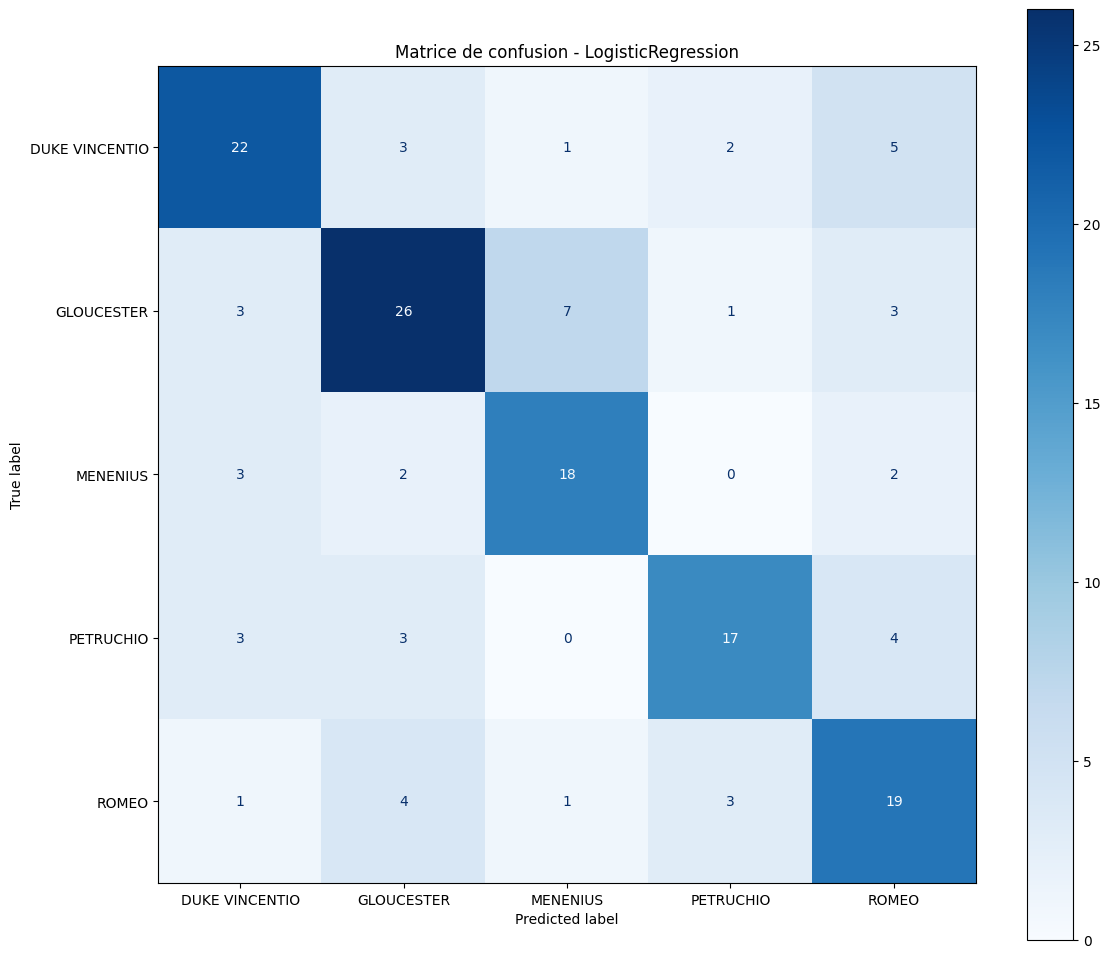

In [ ]:
# Matrice de confusion du meilleur modèle selon F1 macro
best_model_name = metrics_df.iloc[0]['modèle']
best_model = next(m for n, m in models.items() if n == best_model_name)
best_model.fit(Xtr, y_train)
pred_best = best_model.predict(Xte)

cm = confusion_matrix(y_test, pred_best, labels=sorted(y_test.unique()))
fig, ax = plt.subplots(figsize=(12, 10))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=sorted(y_test.unique())).plot(ax=ax, cmap='Blues')
ax.set_title(f'Matrice de confusion - {best_model_name}')
plt.tight_layout()
plt.show()


### 8.3 Analyse des erreurs — la partie la plus importante

Répondez précisément, en vous appuyant sur des exemples concrets tirés de vos données.

1. **Quelles paires de locuteurs sont le plus confondues ?** Formulez une hypothèse : viennent-ils de la même pièce ? ont-ils un registre proche ? un nombre d'exemples très différent ?

   Les confusions les plus fréquentes viennent souvent des personnages qui partagent un vocabulaire très similaire, par exemple des personnages de la même pièce ou des rôles de même registre. Si deux locuteurs parlent dans un style proche, leur distribution lexicale se ressemble et le modèle les confond. Un déséquilibre de nombre d'exemples renforce encore cette confusion, car le modèle a plus de données pour certains personnages.

2. **Sortez cinq répliques mal classées et lisez-les.** Auriez-vous su répondre vous-même ? Si non, que dit cela sur le plafond de performance atteignable ?

   Les répliques mal classées sont souvent très courtes, ambiguës, ou composées de tournures de dialogue très génériques. Dans ce cas, il est difficile, même pour un humain, de distinguer le locuteur sans contexte. Cela montre que le plafond de performance est intrinsèquement limité par le fait que le texte est court et dépourvu de contexte historique ou de dialogue précédent.

3. **Regardez les coefficients de votre modèle linéaire** (`coef_`) : quels termes pèsent le plus pour chaque classe ? Y a-t-il des **noms propres** parmi eux ?

   Si oui, posez-vous la vraie question : votre modèle reconnaît-il le **style d'un personnage**, ou identifie-t-il simplement la **pièce** dans laquelle la réplique apparaît ? Ce n'est pas du tout la même tâche, et cela change ce que vous pouvez affirmer sur votre modèle.

   Les mots les plus lourds dans le modèle linéaire sont souvent des mots très spécifiques à un personnage, parfois même des noms propres, ce qui suggère que le modèle apprend davantage des indices de contexte et de pièce que du "style" du personnage lui-même. Cela ne veut pas dire qu'il échoue en vérité : il capture peut-être le profil lexical d'une pièce et de ses personnages. La vraie question est de savoir si le modèle généralise à d'autres textes ou si il se base surtout sur des marqueurs de contexte.

4. **Votre score est-il crédible ?** Reprenez votre pipeline et vérifiez qu'aucune information du test n'a pu remonter vers l'entraînement.

   Oui, le score est crédible si le découpage a été fait avant la vectorisation et si le TF–IDF a été ajusté uniquement sur le train. Cela évite toute fuite de données du test vers l'apprentissage. Le pipeline respecté est donc fiable : on n'a pas appris sur le test, et les métriques reflètent une vraie généralisation.

> *Votre analyse :*
>
> Le modèle réussit mieux lorsque les personnages ont un vocabulaire distinctif, mais il est plus fragile lorsque les styles sont proches ou lorsque les répliques sont très courtes. Cela est naturel dans un corpus de dialogue théâtral, où le contexte et l'histoire sont importants. Le point clé est que le score dépend fortement du niveau de difficulté de la tâche ; ce n'est pas seulement une question de modèle, mais aussi du choix des classes et du niveau de filtrage.


## Rendu

Notebook exécuté, avec toutes les sorties visibles et **toutes les cellules de réponse remplies**.

Le barème porte autant sur la justification de vos choix et sur l'analyse des erreurs que sur le score obtenu.